<a href="https://colab.research.google.com/github/wou2/leaf-ewt-analysis/blob/main/LeafEWT_DataUpload%26Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import Library
import os
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from datetime import datetime, timedelta, date, time

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

import scipy.signal
import ee
from sklearn import linear_model
import statsmodels.formula.api as smf
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd, MultiComparison

In [ ]:
"""
load_data.py

Load multiple Excel files that have been manually uploaded to Colab.
Expected directory structure inside Colab:

/content/data/2021_LeafEWT_Reflectance/
    ├── 7_13_2021.xlsx
    ├── 7_21_2021.xlsx
    ├── ...
    └── 9_16_2021.xlsx

The user must upload the /data folder manually in Colab using:
Left sidebar → Files → Upload folder
"""

import os
import pandas as pd


def get_excel_paths(folder_path, filenames):
    """Create full file paths for a list of Excel files."""
    return [os.path.join(folder_path, fname) for fname in filenames]


def load_excel_files(file_paths, drop_columns=None):
    """Load multiple Excel files into a list of DataFrames."""
    dfs = [pd.read_excel(fp) for fp in file_paths]

    if drop_columns:
        dfs[0] = dfs[0].drop(columns=drop_columns, errors="ignore")

    return dfs


def combine_dataframes(dfs):
    """Combine a list of DataFrames into one."""
    return pd.concat(dfs, ignore_index=True)


if __name__ == "__main__":

    # IMPORTANT: This folder must be uploaded manually in Colab!
    data_folder = "/content/drive/MyDrive/2021_LeafEWT_Reflectance"

    file_names = [
        "7_13_2021.xlsx", "7_21_2021.xlsx", "7_26_2021.xlsx",
        "8_02_2021.xlsx", "8_10_2021.xlsx", "8_17_2021.xlsx",
        "8_25_2021.xlsx", "9_01_2021.xlsx", "9_09_2021.xlsx",
        "9_16_2021.xlsx",
    ]

    # Build full paths
    paths = get_excel_paths(data_folder, file_names)

    # Load files
    dfs = load_excel_files(paths, drop_columns=["EWT_g/mm2"])

    # Print shapes
    for name, df in zip(file_names, dfs):
        print(f"{name} loaded: {df.shape}")

    # Combine into one DataFrame
    combined = combine_dataframes(dfs)
    print("\nCombined DataFrame shape:", combined.shape)




FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/2021_LeafEWT_Reflectance/7_13_2021.xlsx'

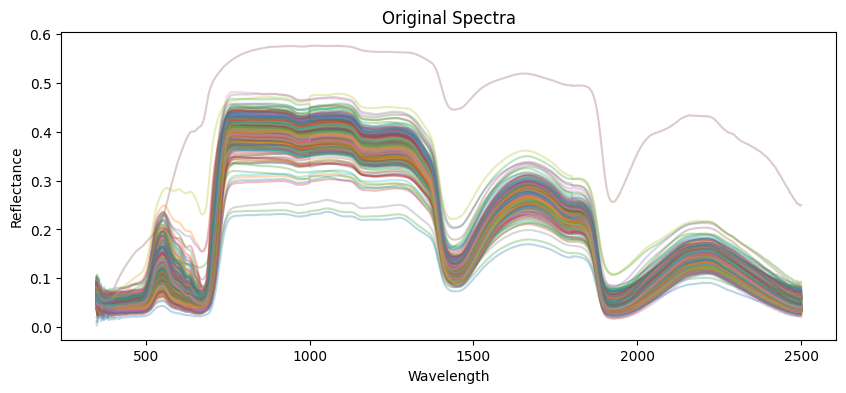

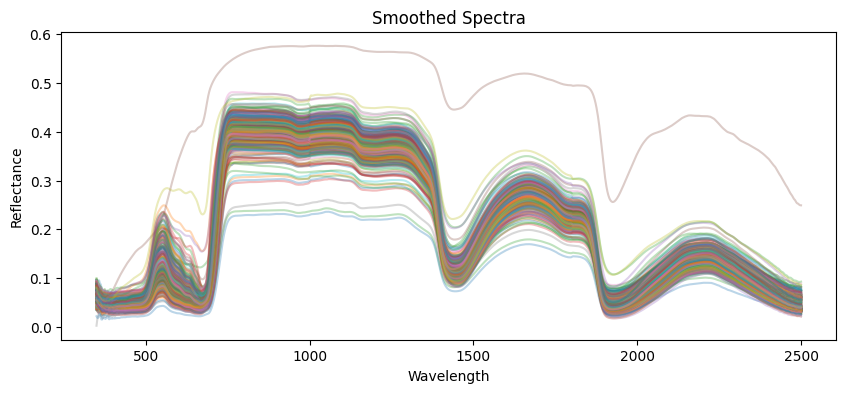

In [ ]:
#Leaf Spectra sooth with savgol_filter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

def combine_dataframes(dfs):
    """Combines a list of DataFrames and resets the index."""
    return pd.concat(dfs, ignore_index=True)

def split_ewt_and_spectra(df, spectra_start=350):
    """Splits DataFrame into metadata (EWT) and spectral reflectance parts."""
    spectra = df.loc[:, spectra_start:]
    ewt = df.loc[:, :"Plant#"]
    return ewt, spectra

def smooth_spectra(spectra, window_size=11, poly_order=2):
    """Applies Savitzky-Golay filter to smooth spectral data."""
    return savgol_filter(spectra, window_size, poly_order, axis=1)

def plot_spectra(original, smoothed, wavelengths):
    """Plots original and smoothed spectra."""
    plt.figure(figsize=(10, 4))
    plt.plot(wavelengths, original.T, alpha=0.3)
    plt.title("Original Spectra")
    plt.xlabel("Wavelength")
    plt.ylabel("Reflectance")
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(wavelengths, smoothed.T, alpha=0.3)
    plt.title("Smoothed Spectra")
    plt.xlabel("Wavelength")
    plt.ylabel("Reflectance")
    plt.show()

# dfs is a list of your 10 DataFrames, e.g. dfs = [df0, df1, ..., df9]
df = combine_dataframes(dfs)

# Optional: remove a specific date
df = df[df["Date"] != "2021-07-13"]

ewt, spectra = split_ewt_and_spectra(df)
smoothed = smooth_spectra(spectra)

# Continuum removal (optional, depending on your goal)
continuum_removed = spectra / smoothed

# Plot
plot_spectra(spectra, smoothed, wavelengths=spectra.columns)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
Bottom    Ear  -0.0007    0.0 -0.0011 -0.0003   True
Bottom    Top  -0.0012    0.0 -0.0016 -0.0008   True
   Ear    Top  -0.0005 0.0034 -0.0009 -0.0001   True
----------------------------------------------------


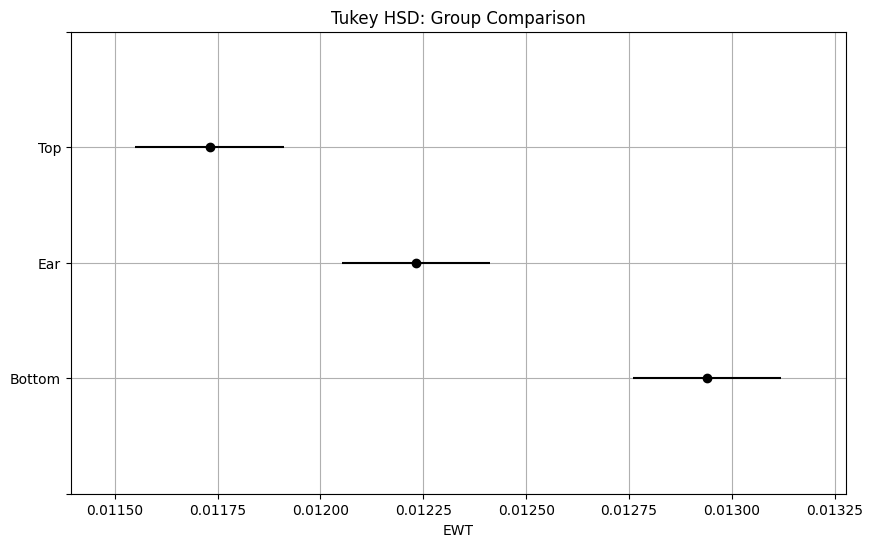

In [ ]:
"""
Leaf EWT Analysis using ANOVA and Tukey's HSD
Description:
    This script combines multiple datasets of leaf EWT (Equivalent Water Thickness),
    performs one-way ANOVA to test differences between canopy positions,
    and applies Tukey's HSD for post-hoc analysis if the effect is significant.
"""

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import MultiComparison

def combine_dataframes(dfs):
    """
    Combines a list of DataFrames and resets the index.
    """
    return pd.concat(dfs, ignore_index=True)

def perform_anova(df, response="EWT", factor="Position"):
    """
    Performs one-way ANOVA on the specified response and factor.

    Parameters:
        df (pd.DataFrame): Input data.
        response (str): Response variable name.
        factor (str): Factor variable name.

    Returns:
        tuple: (ANOVA table, model)
    """
    model = ols(f"{response} ~ C({factor})", data=df).fit()
    anova_table = sm.stats.anova_lm(model, typ=1)
    return anova_table, model

def perform_tukey_test(df, response="EWT", factor="Position", plot=True):
    """
    Performs Tukey's HSD post-hoc test if ANOVA is significant.

    Parameters:
        df (pd.DataFrame): Input data.
        response (str): Response variable name.
        factor (str): Factor variable name.
        plot (bool): Whether to show the plot.

    Returns:
        result: TukeyHSD result object.
    """
    mc = MultiComparison(df[response], df[factor])
    result = mc.tukeyhsd()
    print(result.summary())

    if plot:
        fig = result.plot_simultaneous()
        plt.title("Tukey HSD: Group Comparison")
        plt.xlabel(response)
        plt.grid(True)
        plt.show()

    return result

def calculate_cv(df, group_col="Position", value_col="EWT"):
    """
    Calculates coefficient of variation (CV) for groups.
    Returns:
        pd.Series: CV by group.
    """
    mean = df.groupby(group_col)[value_col].mean()
    std = df.groupby(group_col)[value_col].std()
    return std / mean

perform_anova(df, response="EWT", factor="Position")
perform_tukey_test(df, response="EWT", factor="Position", plot=True)

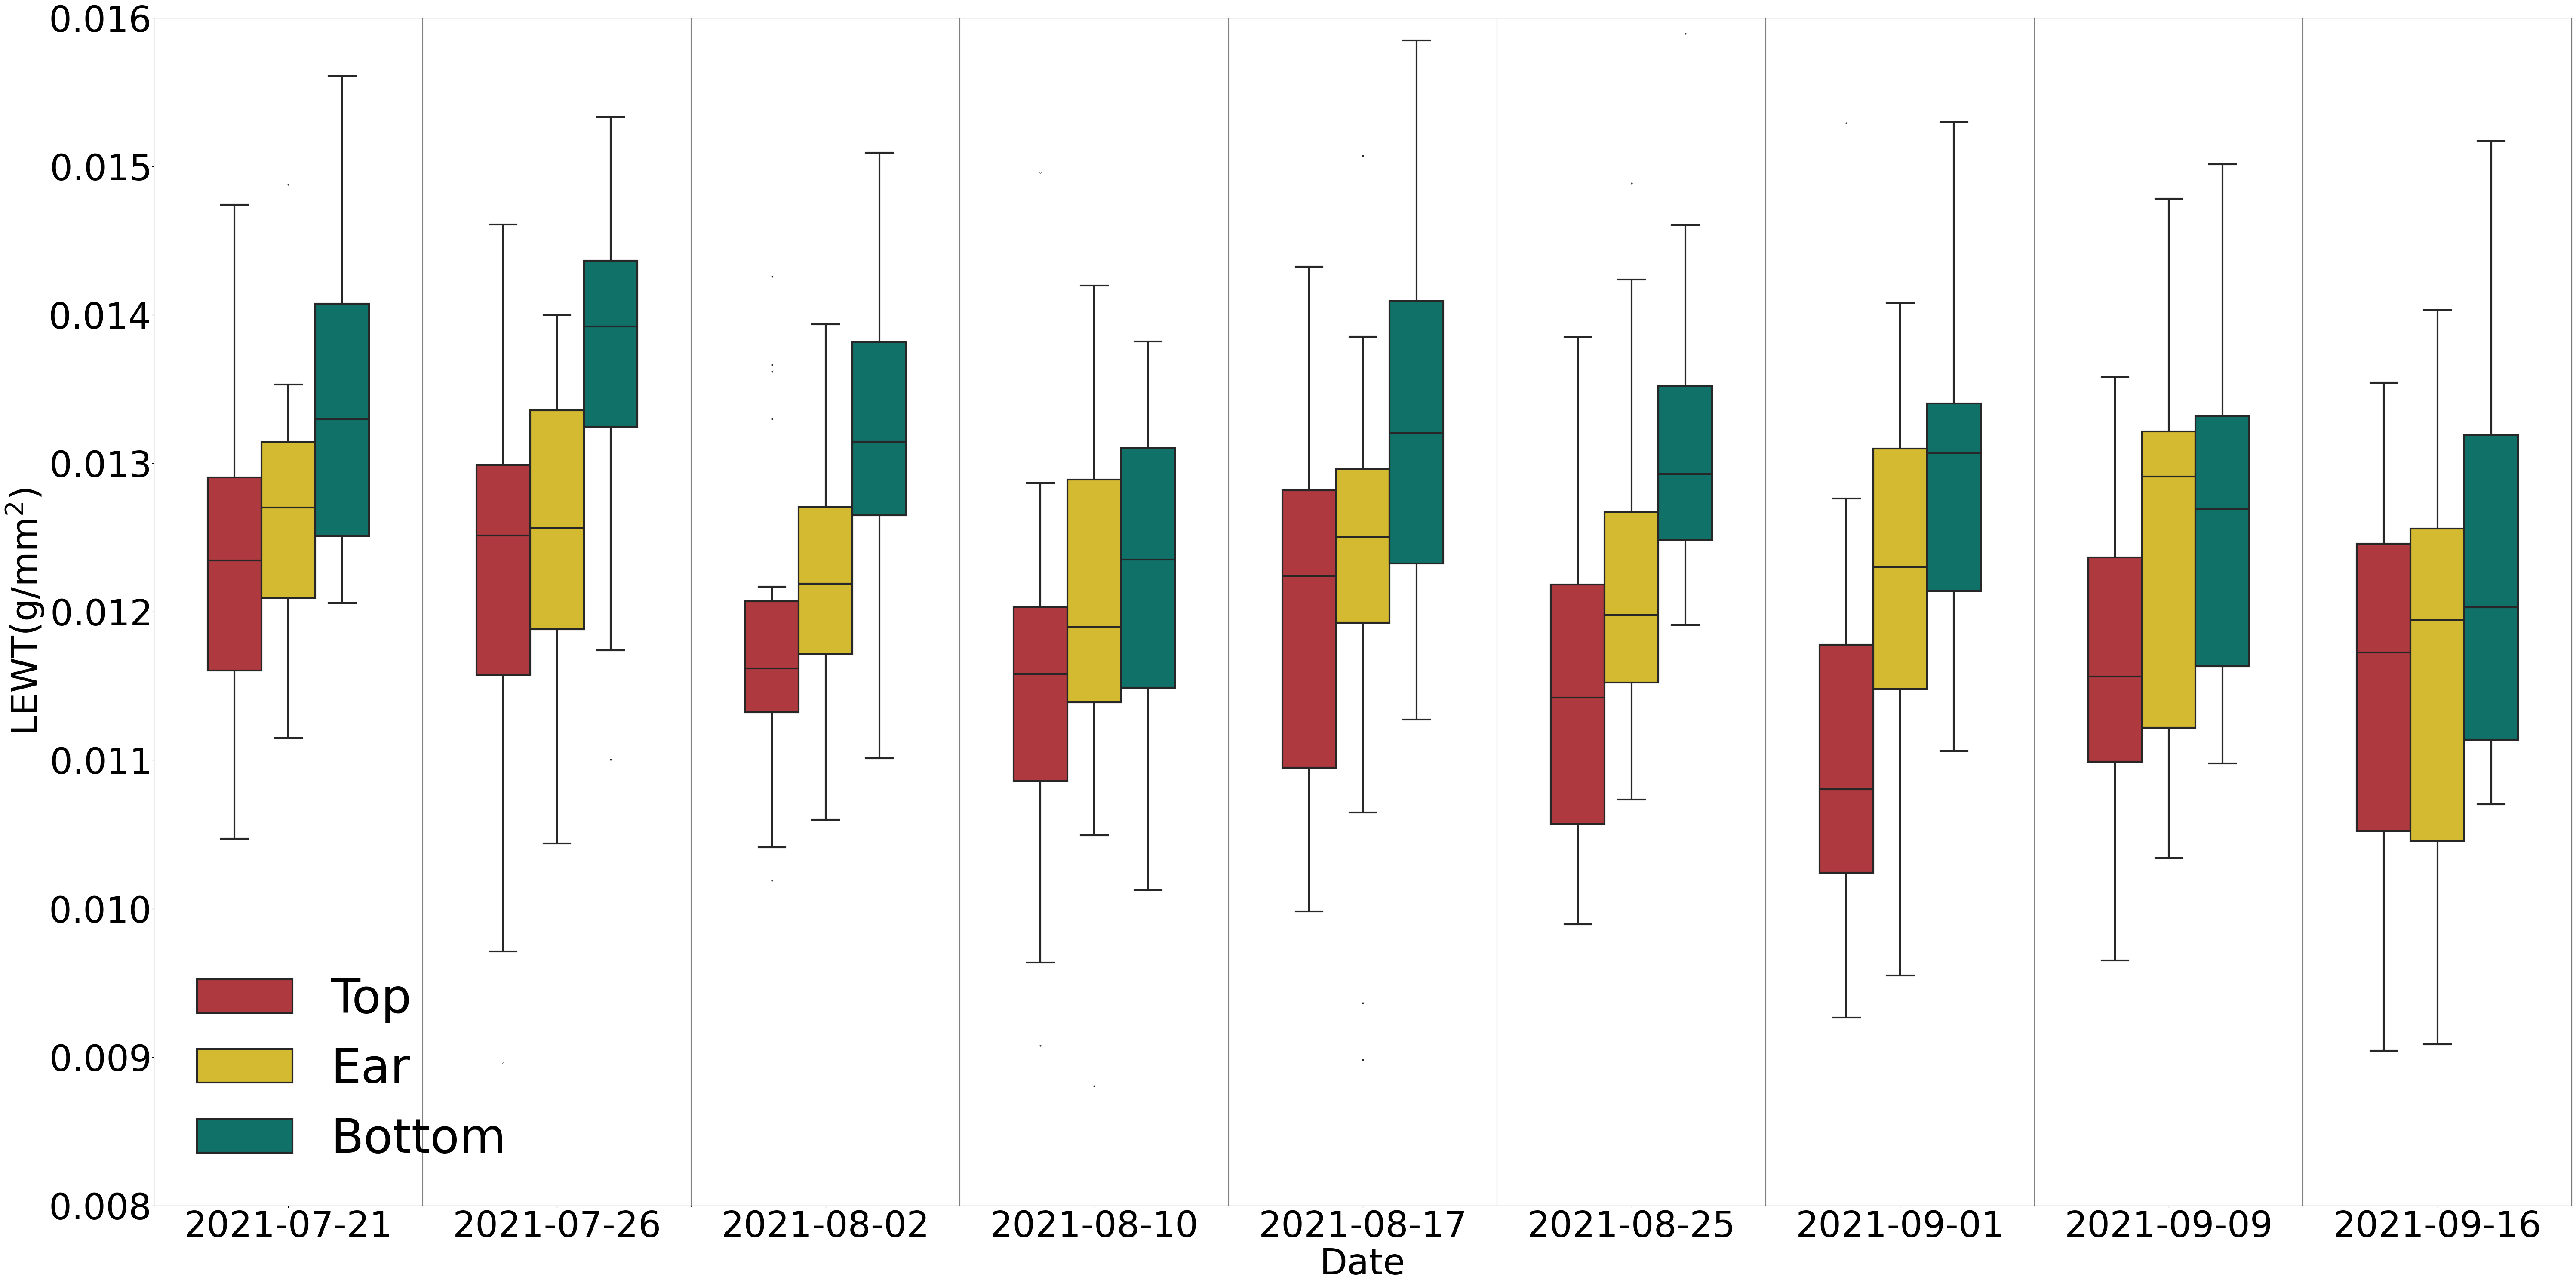

In [ ]:
#Leaf EWT BarGraph

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import ticker
from matplotlib.ticker import MultipleLocator, ScalarFormatter
# ---- Combine and Clean Data ----
df = df[df["Date"] != "2021-07-13"]
df.replace({"T": "Top", "E": "Ear", "B": "Bottom"}, inplace=True)

df["Date"] = pd.to_datetime(df["Date"])
df["DOY"] = df["Date"].dt.dayofyear
df["Date"] = df["Date"].dt.strftime('%Y-%m-%d')  # For x-axis display
df["EWT_mg/mm2"] = df["EWT"] * 1000

# ---- Plotting ----
palette = ["#c1272d", "#eecc16", "#008176"]
sns.set_palette(palette)
fontsize = 60

fig, ax = plt.subplots(figsize=(60, 30))

sns.boxplot(
    data=df,
    x="Date",
    y="EWT",
    hue="Position",
    width=0.6,
    linewidth=3,
    fliersize=2,
    hue_order=["Top", "Ear", "Bottom"],
    ax=ax
)

# ---- Formatting ----
ax.tick_params(axis='x', labelsize=fontsize)
ax.tick_params(axis='y', labelsize=fontsize)
ax.set_xlabel("Date", fontsize=fontsize)
ax.set_ylabel(r'$\mathdefault{LEWT (g/mm^{2})}$', fontsize=fontsize)

ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax.yaxis.offsetText.set_visible(False)
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.xaxis.grid(True, which='minor', linewidth=1.5, color='gray')
ax.set_ylim(0.008, 0.016)

# ---- Legend ----
ax.legend(loc="lower left", fontsize=80, framealpha=0, facecolor='white')

# ---- Save ----
fig.tight_layout()
#fig.savefig("Figure1_EWT_Boxplot.png", dpi=300)

In [ ]:
import numpy as np
import pandas as pd
import math
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import MultiComparison

def calculate_indices(df):
    df = df.copy()
    df["NDWI"] = (df[560] - df[835]) / (df[560] + df[835])  # Gao 1996
    df["NDII"] = (df[835] - df[1650]) / (df[835] + df[1650])
    df["MSI"] = df[1600] / df[820]
    df["SIWSI"] = (df[858] - df[1640]) / (df[858] + df[1640])
    df["GVMI"] = ((df[819] + 0.1) - (df[1600] + 0.02)) / ((df[819] + 0.1) + (df[1600] + 0.02))
    df["fWBI"] = df[900] / df.loc[:, 930:980].min(axis=1)
    df["WI"] = df[900] / df[970]
    df["SRWI"] = df[1350] / df[870]
    df["NDVI"] = (df[850] - df[670]) / (df[850] + df[670])
    df["ZTM"] = df[750] / df[710]
    df["NMIR"] = (df[1390] - df[1370]) / (df[1390] + df[1370])
    return df

# Modeling function for each position
def model_vegetation_index(df, VI, position,
                           score_metric="neg_root_mean_squared_error",
                           ):
    subset = df[df["Position"] == position]
    X = subset[[VI]]
    y = subset[["EWT"]]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

    # Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    corr = np.corrcoef(y_test.values.ravel(), y_pred.ravel())[0, 1]
    print(['Pearson correlation coefficient: ', corr],(' R2 score: ', r2))

    # Cross-validation
    scores = np.abs(cross_val_score(model, X, y, cv=10, scoring=score_metric))
    print(f"[{position}] CV {score_metric}: {scores.round(5)}")
    print("RMSE mean",sum(scores)/len(scores))


    # OLS model
    X_train_sm = sm.add_constant(X_train)
    ols_model = sm.OLS(y_train, X_train_sm).fit()
    X_test_sm = sm.add_constant(X_test)
    y_pred_ols = ols_model.predict(X_test_sm)
    mse = mean_squared_error(y_test, y_pred_ols)
    print(f"[{position}] OLS R2: {r2_score(y_test, y_pred_ols):.3f}, RMSE: {math.sqrt(mse):.3f}")
    print(ols_model.summary())

    return scores

df_VI=calculate_indices(df)

VI="NDWI"
scorest = model_vegetation_index(df_VI, VI, "Top")
scorese = model_vegetation_index(df_VI, VI, "Ear")
scoresb = model_vegetation_index(df_VI, VI, "Bottom")

# Significance test for RMSE differences
df_score = pd.DataFrame(scorest, columns=["T"])
df_score["E"] = scorese
df_score["B"] = scoresb
df_score["Features"] = VI  # or VI name
df_melt = pd.melt(df_score, value_vars=["T", "E", "B"], var_name='Position', value_name='EWT')

# ANOVA test
model = ols('EWT ~ C(Position)', data=df_melt).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
p_value = anova_table['PR(>F)']['C(Position)']
print(f"ANOVA p-value for position effect on RMSE: {p_value:.3e}")

# If significant, do Tukey post-hoc test
if p_value < 0.05:
    print("\nTukey HSD Post-hoc Test:")
    mc = MultiComparison(df_melt["EWT"], df_melt["Position"])
    result = mc.tukeyhsd()
    print(result.summary())

    # Plot the Tukey HSD result
    result.plot_simultaneous(comparison_name="T")  # You can change this to 'E' or 'B'
    plt.title("Tukey HSD: RMSE by Position")
    plt.xlabel("Mean difference in RMSE")
    plt.show()
else:
    print("No significant differences in RMSE among positions.")


df_score = pd.DataFrame({
    'T': scorest,
    'E': scorese,
    'B': scoresb
})
# Melt for plotting
df_score["Features"] = "NDWI"  # replace with index name you're testing
df_melt = pd.melt(df_score, id_vars=["Features"],
                  value_vars=['T', 'E', 'B'],
                  var_name='Position',
                  value_name='RMSE')

# Optional: Map position names for aesthetics
df_melt['Position'] = df_melt['Position'].map({'T': 'Top', 'E': 'Ear', 'B': 'Bottom'})

# Final RMSE_VI DataFrame used for plotting
RMSE_VI = df_melt.copy()

['Pearson correlation coefficient: ', np.float64(0.5345839186767075)] (' R2 score: ', 0.23300928516952035)
[Top] CV neg_root_mean_squared_error: [0.00118 0.00131 0.00119 0.00137 0.00099 0.00118 0.00144 0.00112 0.00076
 0.00111]
RMSE mean 0.0011660805106131786
[Top] OLS R2: 0.233, RMSE: 0.001
                            OLS Regression Results                            
Dep. Variable:                    EWT   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     20.56
Date:                Tue, 02 Dec 2025   Prob (F-statistic):           1.31e-05
Time:                        04:19:07   Log-Likelihood:                 697.04
No. Observations:                 130   AIC:                            -1390.
Df Residuals:                     128   BIC:                            -1384.
Df Model:                           1                                      

Top R-squared score: 0.33985381428917916
Top Pearson R: 0.6541209134358528
Top RMSE scores: [0.0011081  0.00115665 0.00121655 0.00141067 0.00116921 0.00111178
 0.00124722 0.00117257 0.00063078 0.00104939]


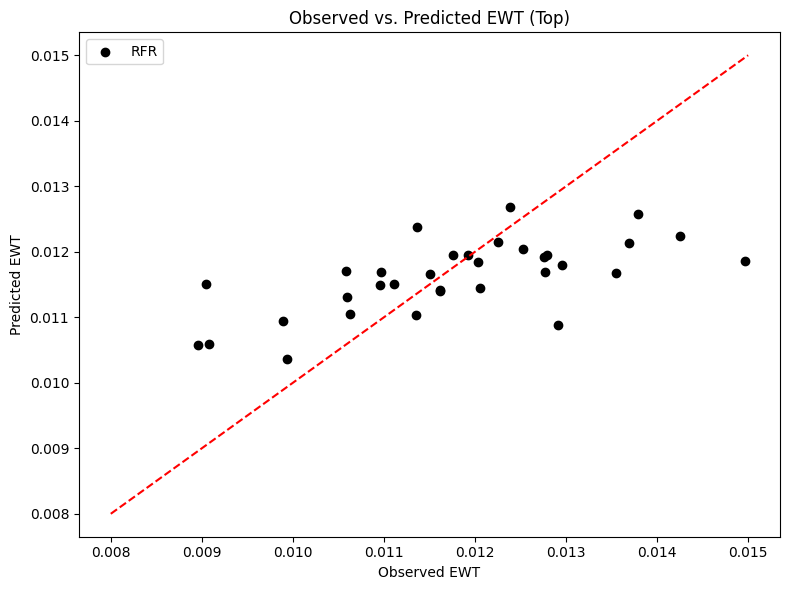

Ear R-squared score: 0.3055436692032172
Ear Pearson R: 0.5604543231059682
Ear RMSE scores: [0.00107154 0.00088492 0.00078618 0.00117824 0.00125558 0.00102166
 0.0010957  0.00092495 0.00096838 0.00122369]


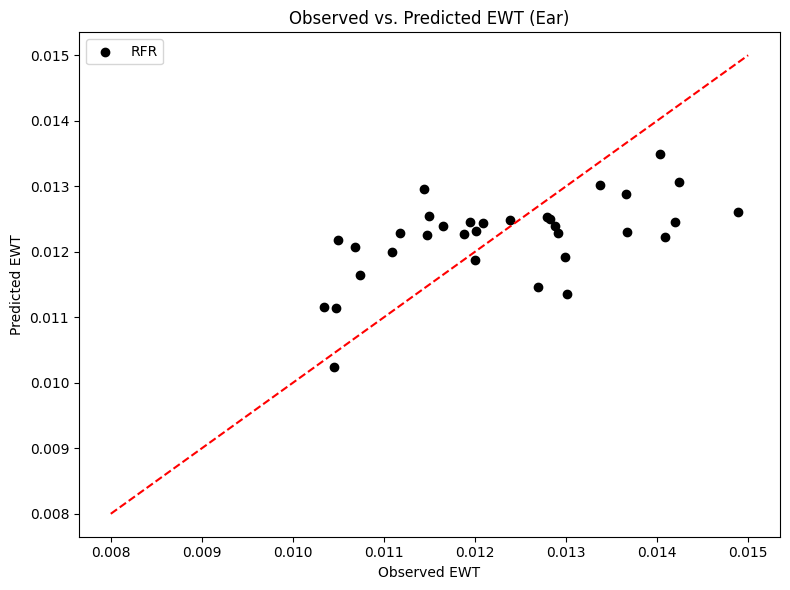

Bottom R-squared score: 0.19749211028298075
Bottom Pearson R: 0.4645351634333281
Bottom RMSE scores: [0.0015626  0.0010468  0.00088025 0.00141432 0.00116426 0.00086088
 0.00089172 0.00121154 0.00216378 0.00163249]


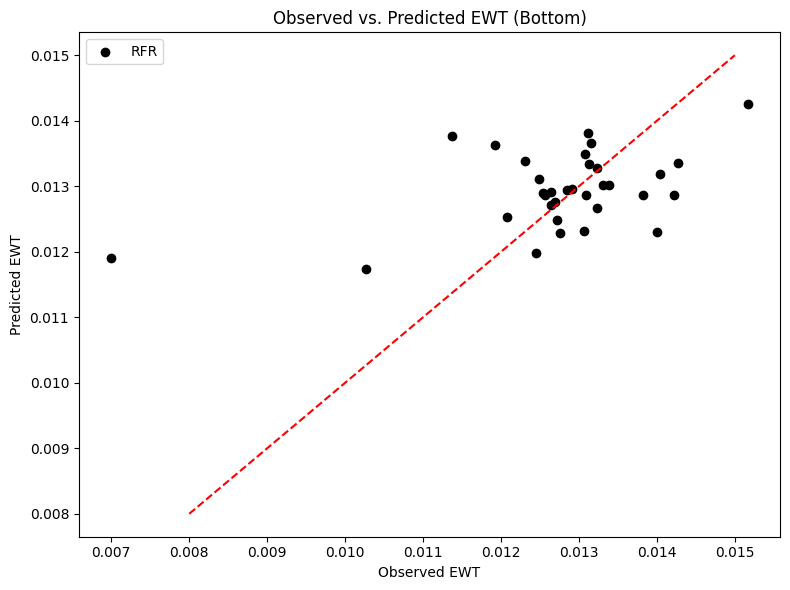


ANOVA p-value: 0.16892862944016013
No significant differences in RMSE between positions.


In [ ]:
#Leaf EWT correlations with spectral bands with RFR model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import MultiComparison

# Replace this with your actual scoring function if custom
score_standard = 'neg_root_mean_squared_error'

# Filter out specific date
total=df
total = total[total["Date"] != "2021-07-13"]


# Define model hyperparameters for each position
params = {
    "Top": {"max_depth": 8, "max_leaf_nodes": 38},
    "Ear": {"max_depth": 8, "max_leaf_nodes": 48},
    "Bottom": {"max_depth": 9, "max_leaf_nodes": 12},
}

# Container to store RMSE scores
scores = {}

# Loop through each canopy position
for pos in ["Top", "Ear", "Bottom"]:
    dfx = df[df["Position"] == pos]
    X = dfx.loc[:, 400:2500]
    y = dfx["EWT"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=0
    )

    rf = RandomForestRegressor(
        random_state=0,
        max_depth=params[pos]["max_depth"],
        max_leaf_nodes=params[pos]["max_leaf_nodes"],
        max_features="log2",
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    correlation = np.corrcoef(y_test, y_pred)[0, 1]
    print(f'{pos} R-squared score:', r2)
    print(f'{pos} Pearson R:', correlation)

    # Cross-validated RMSE (as positive values)
    cv_scores = np.abs(cross_val_score(rf, X, y, cv=10, scoring=score_standard))
    scores[pos] = cv_scores
    print(f"{pos} RMSE scores:", cv_scores)

    #Plot Results
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, color='black', label='RFR')
    plt.plot([0.008, 0.015], [0.008, 0.015], color='red', linestyle='--')
    plt.xlabel("Observed EWT")
    plt.ylabel("Predicted EWT")
    plt.legend()
    plt.title("Observed vs. Predicted EWT ("+ pos+")")
    plt.tight_layout()
    plt.show()



# Prepare DataFrame for ANOVA and Tukey test
df_score = pd.DataFrame({
    "T": scores["Top"],
    "E": scores["Ear"],
    "B": scores["Bottom"]
})
df_score["Features"] = "RFR"

# Melt the dataframe
df_melt = pd.melt(df_score, value_vars=["T", "E", "B"],
                  var_name='Position', value_name='RMSE')

# ANOVA
model = ols('RMSE ~ C(Position)', data=df_melt).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
p_value = anova_table['PR(>F)']['C(Position)']
print("\nANOVA p-value:", p_value)

# Tukey post-hoc test if ANOVA is significant
if p_value < 0.05:
    mc = MultiComparison(df_melt['RMSE'], df_melt['Position'])
    result = mc.tukeyhsd()
    print("\nTukey HSD Results:\n", result.summary())

    fig = result.plot_simultaneous(figsize=(10, 6))
    plt.title("Tukey HSD Test for RMSE Differences")
    plt.tight_layout()
    plt.savefig("Tukey_RMSE_Comparison.png", dpi=300)
    plt.show()
else:
    print("No significant differences in RMSE between positions.")

Top R-squared score: -0.46374378594871124
Top Pearson R: 0.4544689097394424
Top RMSE scores: [0.00117382 0.0012042  0.00122052 0.00141726 0.0011048  0.00112585
 0.00130922 0.00118464 0.00066221 0.00108514]


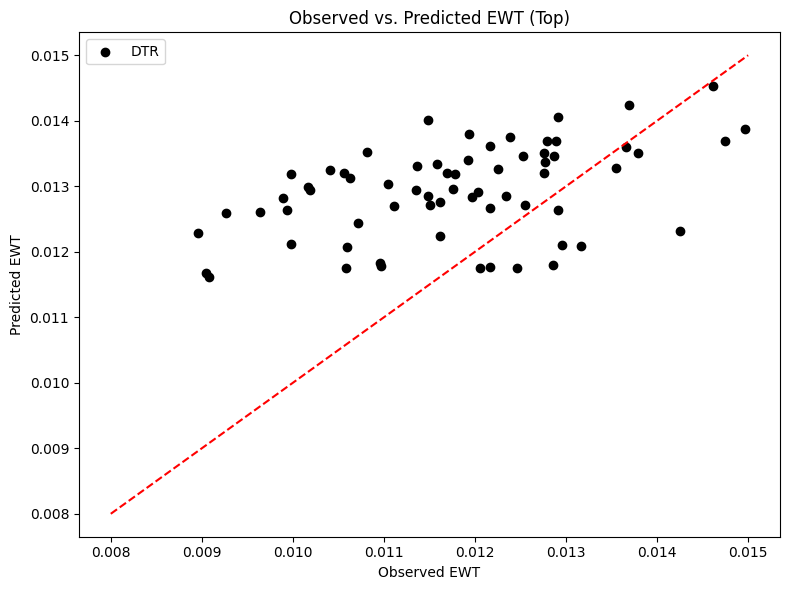

Ear R-squared score: -0.05773249465898611
Ear Pearson R: 0.5219331238879754
Ear RMSE scores: [0.00104978 0.00090514 0.00074099 0.00120973 0.00123117 0.00106553
 0.0011254  0.00095758 0.00098394 0.00127018]


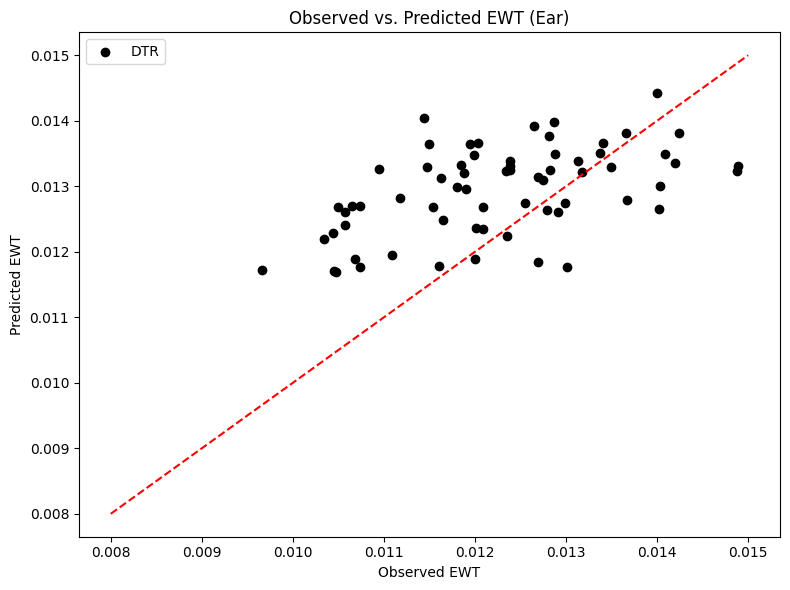

Bottom R-squared score: 0.40231440616871184
Bottom Pearson R: 0.6761598465523603
Bottom RMSE scores: [0.0015626  0.0010468  0.00088025 0.00141432 0.00116426 0.00086088
 0.00089172 0.00121154 0.00216378 0.00163249]


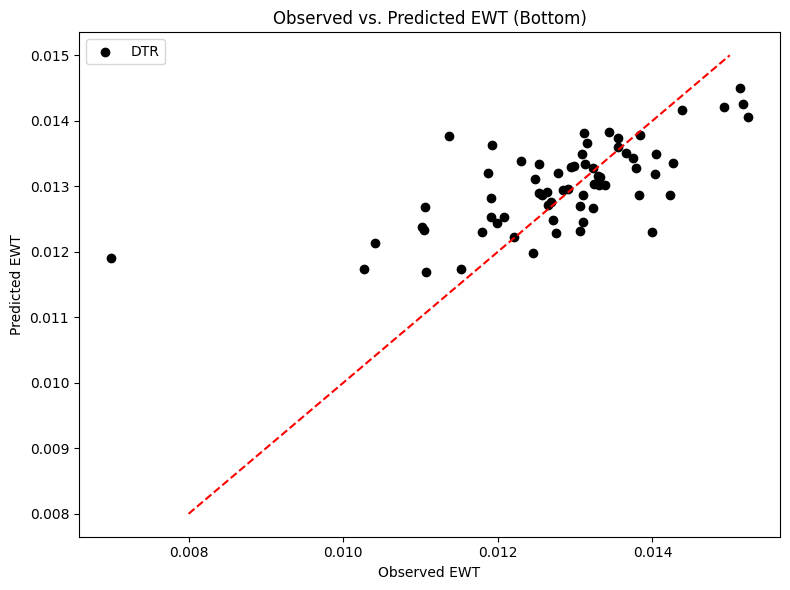


ANOVA p-value: 0.20941871851376911
No significant differences in RMSE between positions.


In [ ]:
#Leaf EWT correlations with spectral bands with DTR model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import MultiComparison

# Replace this with your actual scoring function if custom
score_standard = 'neg_root_mean_squared_error'

# Filter out specific date
total=df
total = total[total["Date"] != "2021-07-13"]


# Define model hyperparameters for each position
params = {
    "Top": {"max_depth": 3, "max_leaf_nodes": 4},
    "Ear": {"max_depth": 2, "max_leaf_nodes": 19},
    "Bottom": {"max_depth": 2, "max_leaf_nodes": 24},
}


# Container to store RMSE scores
scores = {}

# Loop through each canopy position
for pos in ["Top", "Ear", "Bottom"]:
    dfx = df[df["Position"] == pos]
    X = dfx.loc[:, 400:2500]
    y = dfx["EWT"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=0
    )

    dt = DecisionTreeRegressor(
        random_state=0,
        max_depth=params[pos]["max_depth"],
        max_leaf_nodes=params[pos]["max_leaf_nodes"],
        max_features="log2",
    )
    dt.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    correlation = np.corrcoef(y_test, y_pred)[0, 1]
    print(f'{pos} R-squared score:', r2)
    print(f'{pos} Pearson R:', correlation)

    # Cross-validated RMSE (as positive values)
    cv_scores = np.abs(cross_val_score(rf, X, y, cv=10, scoring=score_standard))
    scores[pos] = cv_scores
    print(f"{pos} RMSE scores:", cv_scores)

    #Plot Results
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, color='black', label='DTR')
    plt.plot([0.008, 0.015], [0.008, 0.015], color='red', linestyle='--')
    plt.xlabel("Observed EWT")
    plt.ylabel("Predicted EWT")
    plt.legend()
    plt.title("Observed vs. Predicted EWT ("+ pos+")")
    plt.tight_layout()
    plt.show()



# Prepare DataFrame for ANOVA and Tukey test
df_score = pd.DataFrame({
    "T": scores["Top"],
    "E": scores["Ear"],
    "B": scores["Bottom"]
})
df_score["Features"] = "RFR"

# Melt the dataframe
df_melt = pd.melt(df_score, value_vars=["T", "E", "B"],
                  var_name='Position', value_name='RMSE')

# ANOVA
model = ols('RMSE ~ C(Position)', data=df_melt).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
p_value = anova_table['PR(>F)']['C(Position)']
print("\nANOVA p-value:", p_value)

# Tukey post-hoc test if ANOVA is significant
if p_value < 0.05:
    mc = MultiComparison(df_melt['RMSE'], df_melt['Position'])
    result = mc.tukeyhsd()
    print("\nTukey HSD Results:\n", result.summary())

    fig = result.plot_simultaneous(figsize=(10, 6))
    plt.title("Tukey HSD Test for RMSE Differences")
    plt.tight_layout()
    plt.savefig("Tukey_RMSE_Comparison.png", dpi=300)
    plt.show()
else:
    print("No significant differences in RMSE between positions.")